In [1]:
import os
current_path = os.path.abspath(os.getcwd())


import project_images_loader as pil
import numpy as np
import utils.util as util

import utils.functions as fc
import utils.nifti_functions as nfc
import utils.util_freesurfer_segmentation as ufs
import matplotlib.pyplot as plt  
from data_loaders.data_loader_complete import DataLoaderComplete 
from skimage.metrics import structural_similarity as ssim



SERVER: False


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


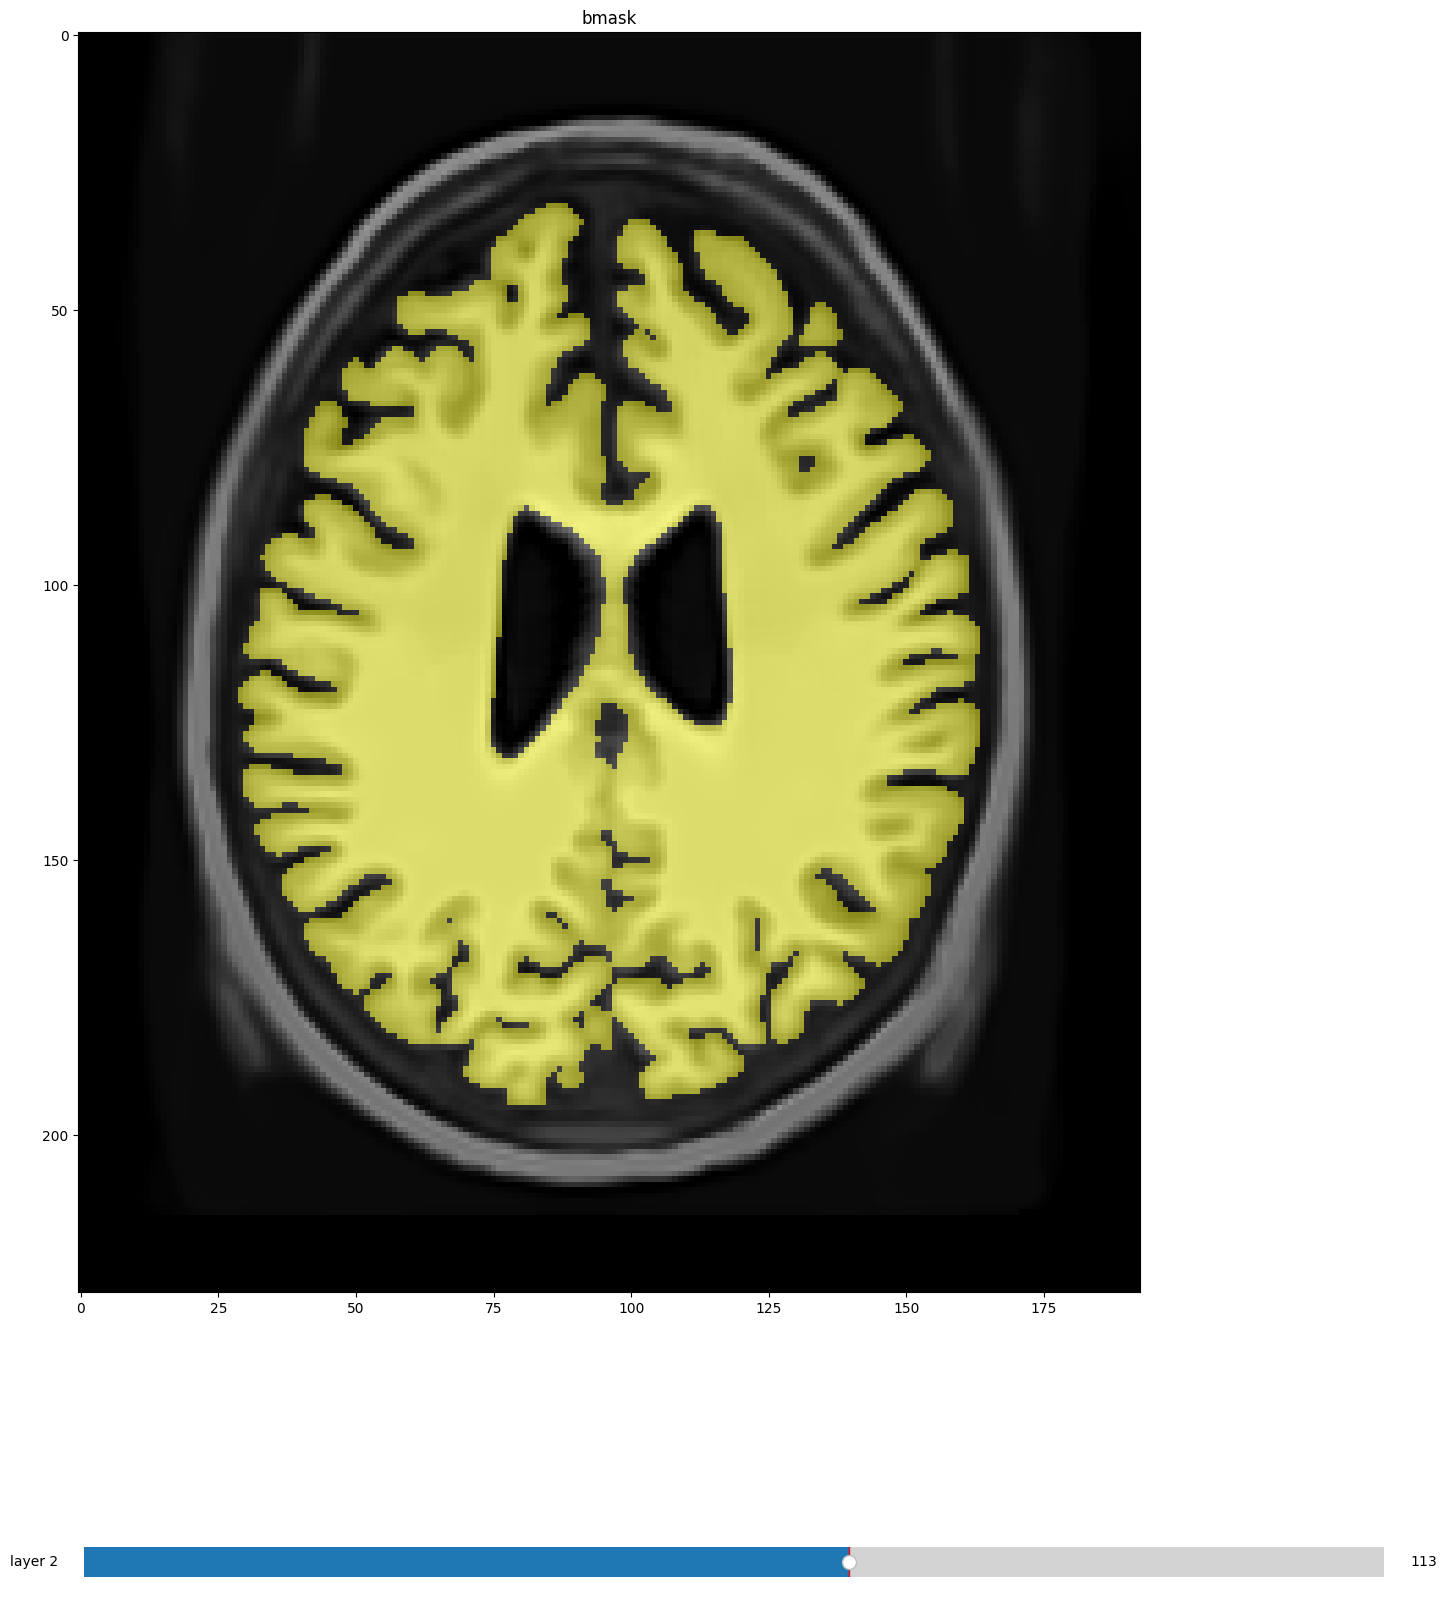

In [15]:
hunt = 4
img, _ = nfc.load_nifti(pil.get_registered_to_template_image_path_name(hunt, "17112", pil.REGISTRATION_TO_MNI, absolute=True))
seg, _ = nfc.load_nifti(pil.get_segmentation_path_name(hunt, "17112", 3, absolute=True))
bmask, _ = nfc.load_nifti(pil.get_brain_mask_path_name(hunt, "17112", pil.REGISTRATION_TO_MNI, no_cerebellum=False, absolute=True))
bmask_ncreb, _ = nfc.load_nifti(pil.get_brain_mask_path_name(hunt, "17112", pil.REGISTRATION_TO_MNI, no_cerebellum=True, absolute=True))
bmask_seg = np.where(seg > 1, 1, 0)
# bmask_seg[seg == 1] = 2
color_dict = {1:(100,100,0), 2:(0,100,100)}


img = np.stack([img, img, img], axis=3)
bmask_seg_rgb = ufs.seg_to_rgbseg(bmask_seg, color_dict).astype(np.float32)
img += bmask_seg_rgb 

img = img / np.max(img) 

fc.imgshow_3D("bmask", img, current_plane=113, figsize=(20,20))

0.9624183219126426
0.9656939751439586


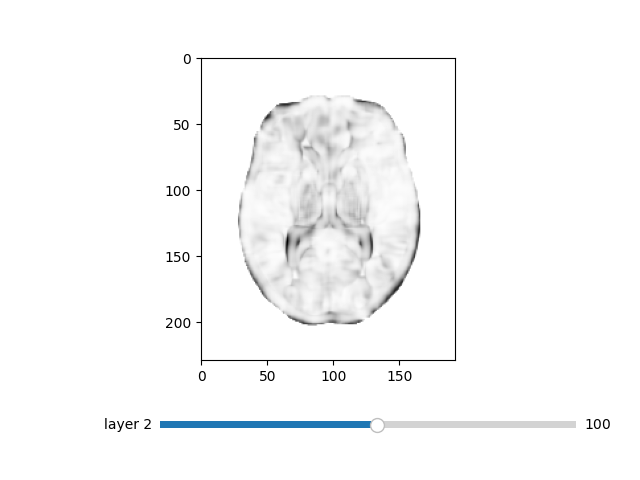

In [8]:
%matplotlib widget
img, _ = pil.load_preprocessed_image(4, "08202")
imgh3, _ = pil.load_preprocessed_image(3, "08202")
# print(img.shape)
# slide = fc.extract_layer(img, 116, 0)
# print(slide.shape)
# plt.imshow(slide, cmap="gray")

# fc.imgshow("", )
ssim_index, ssim_image = ssim(imgh3, img, full=True, data_range=(img.max() - img.min()))
print(ssim_index)
print(np.mean(ssim_image[ssim_image>0]))
fc.imgshow_3D("", ssim_image)

In [18]:
%matplotlib widget
matching_ids = pil.get_matching_ids()
id_index = 302
id = matching_ids[id_index]
hunt = 4
current_plane = 116

In [25]:
def shows_4_images(img_hunt3, img_hunt4, seg_hunt3, seg_hunt4, current_plane=108):
    if img_hunt3.ndim == 3:
        img_hunt3 = img_hunt3[..., current_plane]
        img_hunt4 = img_hunt4[..., current_plane]
        seg_hunt3 = seg_hunt3[..., current_plane, :]
        seg_hunt4 = seg_hunt4[..., current_plane, :]

    img_hunt3 = np.flip(img_hunt3.T)
    img_hunt4 = np.flip(img_hunt4.T)
    seg_hunt3 = np.flip(seg_hunt3.transpose(1, 0, 2))
    seg_hunt4 = np.flip(seg_hunt4.transpose(1, 0, 2))

    fig, axs = plt.subplots(2, 2, figsize=(12, 12))
    fc.imgshow_matplotlib(f"HUNT3", img_hunt3, subplot=axs[0][1])
    fc.imgshow_matplotlib(f"HUNT4", img_hunt4, subplot=axs[0][0])
    fc.imgshow_matplotlib(f"SEG HUNT3", seg_hunt3, subplot=axs[1][0])
    fc.imgshow_matplotlib(f"SEG HUNT4", seg_hunt4, subplot=axs[1][1])

    plt.show()

In [20]:
img_hunt3, affine = nfc.load_nifti(pil.get_preprocessed_image_path_name(3, id, absolute=True))
img_hunt4, affine = nfc.load_nifti(pil.get_preprocessed_image_path_name(4, id, absolute=True))
# fc.imgshow_3D("img", img, current_plane=current_plane)

In [21]:
seg_hunt3, _ = nfc.load_nifti(pil.get_segmentation_path_name(hunt, id, simple=True, absolute=True))
seg_hunt4, _ = nfc.load_nifti(pil.get_segmentation_path_name(hunt, id, simple=True, absolute=True))
seg_hunt3 = ufs.seg_to_rgbseg(seg_hunt3)
seg_hunt4 = ufs.seg_to_rgbseg(seg_hunt4)
# fc.imgshow_3D("", seg, current_plane=current_plane)

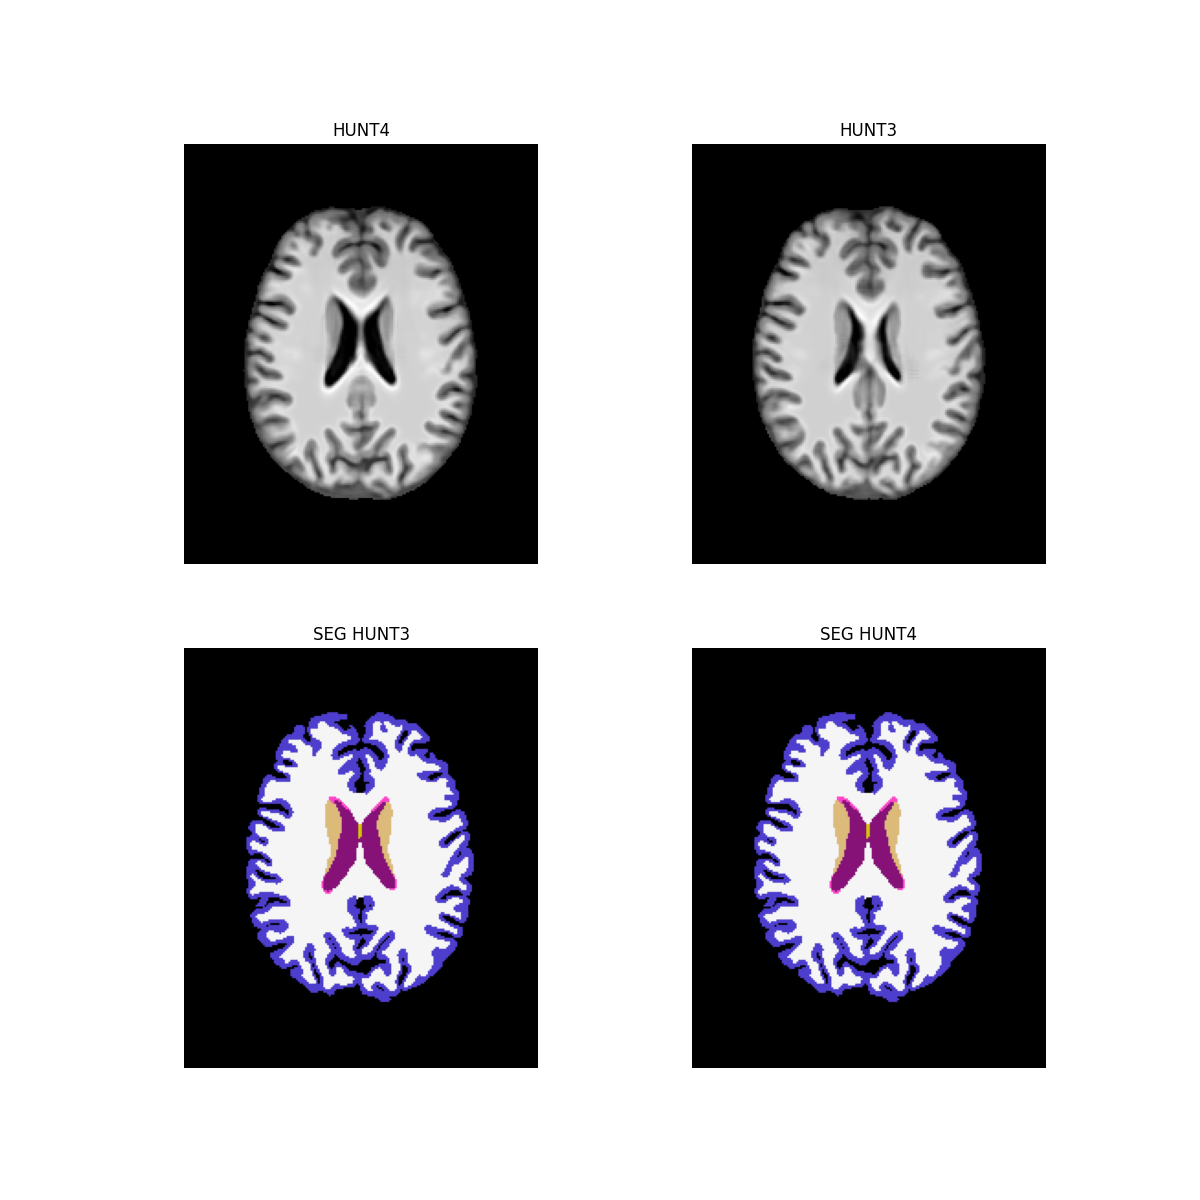

In [26]:
shows_4_images(img_hunt3, img_hunt4, seg_hunt3, seg_hunt4, current_plane=current_plane)

0.0 1.0


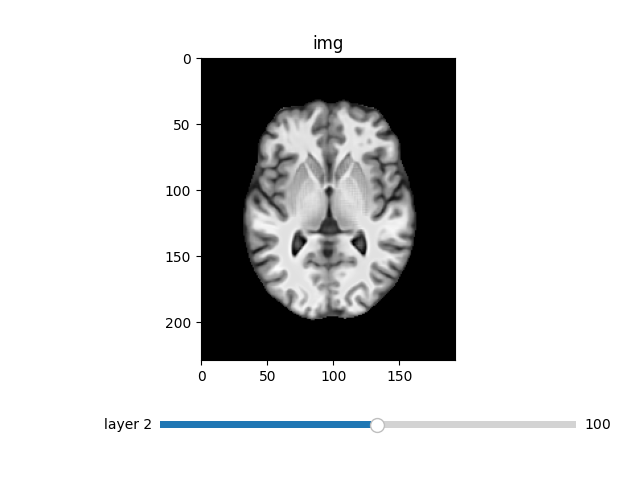

In [5]:




img, affine = nfc.load_nifti(pil.get_preprocessed_image_path_name(hunt, id, absolute=True))
# img, affine = nfc.load_nifti(pil.get_registered_to_template_image_path_name(hunt, id, pil.REGISTRATION_TO_MNI, absolute=True))
# mask, affine = nfc.load_nifti(pil.get_brain_mask_path_name(hunt, id, pil.REGISTRATION_TO_MNI, absolute=True))

# img[mask == 0] = 0
# img = util.skull_stripping_and_normalize(img, mask, remove_negatives=False)
print(img.min(), img.max())

fc.imgshow_3D("img", img)

In [ ]:
def get_algo():
    print("HOLA")
    for i in range(10):
        yield i

HOLA = [e for e in get_algo()]
print(HOLA)
print(HOLA)

HOLA
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [ ]:

%matplotlib widget
# print(f"{pil.get_base_folder()}data_test")
data_train = DataLoader(f"{pil.get_base_folder()}data/data_reduced/train", batch_size=1, image_size=(200, 240, 240), shuffle=True)
data = data_train[0]

# dloader = DataLoader(root_folder=f"data_test", batch_size=3, image_size=(200, 240, 240))
# fc.imgshow_3D(f"Original", data[0][0,0], current_plane=150)



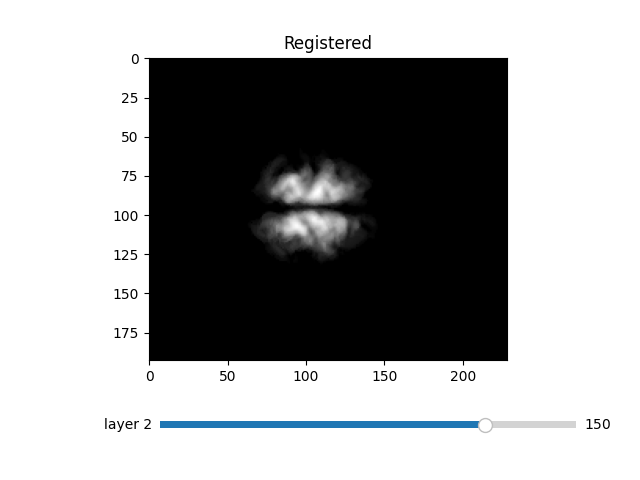

In [ ]:
# check registration results
img_sum = None
for id in pil.test_patients_ids:
    for hunt in pil.HUNTS:
    # for hunt in [4]:

        img, _ = pil.load_registered_image(hunt, id, pil.REGISTRATION_TO_MNI, pil.PARAMETERS_FILE_SIMILARITY)
        if img_sum is None:
            img_sum = img
        else:
            img_sum += img
%matplotlib widget
fc.imgshow_3D(f"Registered", img_sum, current_plane=150)

In [ ]:

        
# img_org, _ = pil.load_original_image(4, 12082, absolute=True)
# img_synthsr, _ = pil.load_image(4, 12082, "12082_1_T1_SYNTHSR.nii")
# img_nsk, _ = pil.load_nsk_image(4, 12082)
# img_prep, aff1 = pil.load_image(4, 12082, "12082_1_T1_PREP.nii")
# img_reg, aff2 = pil.load_image(4, 12082, "12082_1_T1_REG_SIM.nii", absolute=True)

# img_mask, _ = pil.load_brain_mask_image(4, 12082)
# img_mask_reg, aff3 = pil.load_image(4, 12082, "12082_1_BMASK_REG_SIM.nii")

# print(img_reg.shape)

# print(f"Original\tmin: {np.min(img_org)}\tmax:{np.max(img_org)}")
# print(f"synthsr\tmin: {np.min(img_synthsr)}\tmax:{np.max(img_synthsr)}")
# print(f"nsk\tmin: {np.min(img_nsk)}\tmax:{np.max(img_nsk)}")
# print(f"prep\tmin: {np.min(img_prep)}\tmax:{np.max(img_prep)}")
# print(f"mask\tmin: {np.min(img_mask)}\tmax:{np.max(img_mask)}\tunique:{np.unique(img_mask, return_counts=True)}")

# print(f"reg\tmin: {np.min(img_reg)}\tmax:{np.max(img_reg)}")
# print(f"mask_reg\tmin: {np.min(img_mask_reg)}\tmax:{np.max(img_mask_reg)}\tunique:{np.unique(img_mask_reg, return_counts=True)}")



# registrqtion metrics

# img_hunt3_prep, aff2 = pil.load_image(3, 12082, "12082_0_T1_PREP.nii")
# img_hunt3_reg, aff2 = pil.load_image(3, 12082, "12082_0_DFIELD_REGIMAGE_ELASTIX.nii")
# img_hunt4_reg, aff2 = pil.load_image(4, 12082, "12082_1_T1_REG_SIM.nii")



# rms1, ncc1, mi1, joint_hist1 = util.get_metrics_list(img_hunt4_reg, img_hunt3_prep)
# rms2, ncc2, mi2, joint_hist2 = util.get_metrics_list(img_hunt4_reg, img_hunt3_reg)

# print(rms1, ncc1, mi1,)
# print()
# print(rms2, ncc2, mi2,)



# 0.0 1.0 1.517183275008589

# 5.4127193585302e-05 0.9323773011661594 0.7570804987610571

# 0.07630333695521704 0.959917740771932 -0.013074555274402044


